In [11]:
from ucimlrepo import fetch_ucirepo  
# fetch dataset 
wine_quality = fetch_ucirepo(id=186)  
# data (as pandas dataframes) 
X = wine_quality.data.features 
y = wine_quality.data.targets 
# metadata 
print(wine_quality.metadata) 
# variable information 
print(wine_quality.variables) 

{'uci_id': 186, 'name': 'Wine Quality', 'repository_url': 'https://archive.ics.uci.edu/dataset/186/wine+quality', 'data_url': 'https://archive.ics.uci.edu/static/public/186/data.csv', 'abstract': 'Two datasets are included, related to red and white vinho verde wine samples, from the north of Portugal. The goal is to model wine quality based on physicochemical tests (see [Cortez et al., 2009], http://www3.dsi.uminho.pt/pcortez/wine/).', 'area': 'Business', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Multivariate'], 'num_instances': 4898, 'num_features': 11, 'feature_types': ['Real'], 'demographics': [], 'target_col': ['quality'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2009, 'last_updated': 'Wed Nov 15 2023', 'dataset_doi': '10.24432/C56S3T', 'creators': ['Paulo Cortez', 'A. Cerdeira', 'F. Almeida', 'T. Matos', 'J. Reis'], 'intro_paper': {'ID': 252, 'type': 'NATIVE', 'title': 'Modeling wine preferences

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split

In [13]:
def recodificar(q):
    if q <= 5:
        return "ruim"
    elif q <= 7:
        return "médio"
    return "bom"
yr = y['quality'].apply(recodificar)
yr.value_counts()

quality
médio    3915
ruim     2384
bom       198
Name: count, dtype: int64

o knn depende do cálculo de distancias para encontrar os vizinhos mais próximos, então a escala pode influir muito no resultado pois valores com maior magnitude vão dominar o cálculo na distanciar, enquanto uma variável com intervalo de valores menores vão ter menor influência no calculo.

In [18]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, yr, test_size=0.2, random_state=42, stratify=y
)
print(f"Tamanho do dataset = {X.shape[0]} amostras")
print(f"Quantidade de amostras de treinamento = {X_train.shape[0]} amostras")
print(f"Quantidade de amostras de teste = {X_test.shape[0]} amostras")

Tamanho do dataset = 6497 amostras
Quantidade de amostras de treinamento = 5197 amostras
Quantidade de amostras de teste = 1300 amostras


In [30]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score
valores_k = [1, 3, 5, 7, 11]

acuracias_medias = []
for k in valores_k:
    knn = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='accuracy')
    media_acuracia = scores.mean()
    acuracias_medias.append(media_acuracia)
    print(f"Valor de k = {k}, acurácia média = {media_acuracia:.4f}")

Valor de k = 1, acurácia média = 0.7341
Valor de k = 3, acurácia média = 0.7129
Valor de k = 5, acurácia média = 0.7148
Valor de k = 7, acurácia média = 0.7191
Valor de k = 11, acurácia média = 0.7112


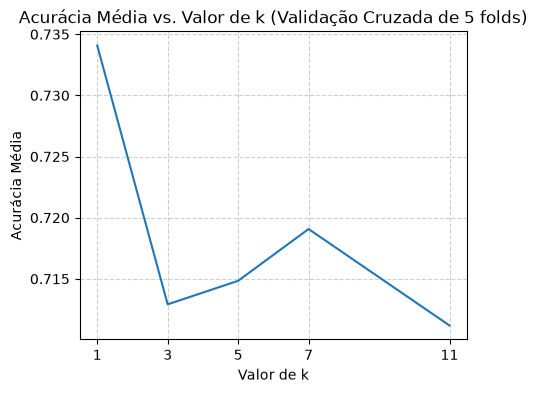

In [28]:
plt.figure(figsize=(5, 4))
plt.plot(valores_k, acuracias_medias)
plt.title('Acurácia Média vs. Valor de k (Validação Cruzada de 5 folds)', fontsize=12)
plt.xlabel('Valor de k')
plt.ylabel('Acurácia Média')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xticks(valores_k)
plt.show()

podemos concluir que o melhor valor de k é 1 pois ele obtém a melhor acurácia média.
para valores baixo de k o modelo aprende excessivamente os detalhes e os ruídos específicos do conjunto de treinamento. Já com uma valores de k maiores, o modelos considera muitos k-vizinhos, diluindo as características, o modelo fica invesado pela maioria.

In [31]:
knn_final = KNeighborsClassifier(n_neighbors= 1)
knn_final.fit(X_train, y_train)
y_pred = knn_final.predict(X_test)

In [36]:
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
metricas = classification_report(y_test, y_pred)
print(metricas)

              precision    recall  f1-score   support

         bom       0.45      0.53      0.48        40
       médio       0.79      0.80      0.79       783
        ruim       0.71      0.69      0.70       477

    accuracy                           0.75      1300
   macro avg       0.65      0.67      0.66      1300
weighted avg       0.75      0.75      0.75      1300



In [48]:
print(x)

[[331 145   1]
 [135 623  25]
 [  2  17  21]]


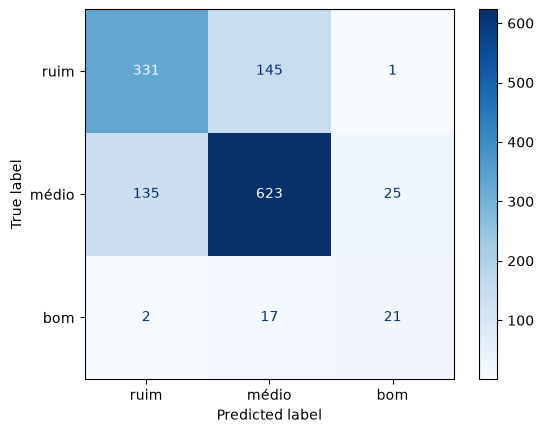

In [47]:
classes = ['ruim', 'médio', 'bom']
x = confusion_matrix(y_test, y_pred, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=x, display_labels=classes)
disp.plot(cmap='Blues')
plt.show()

O modelo erra mais entre as classes médio e ruim, isso se por essa serem as classes majoritárias e da proximidade das notas 5 e 6.